# Approach B: Calories Burned **per Hour**
**Question:** if we remove session length, what makes someone burn calories *faster*?

`Cal_per_Hour = Calories_Burned / Session_Duration`. This measures **intensity**, not how long someone stayed.

Sections:
1. Distribution of calories per hour
2. Workout type: the red flag
3. Heart rate vs calories per hour, by gender
4. What drives calories per hour? (factor effects)
5. Experience stops mattering
6. Low / Mid / High intensity tiers
7. Revisiting the 1,500+ sessions per hour

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import cross_val_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("https://raw.githubusercontent.com/salioudunn11/Fitness_Prediction/main/gym_members_exercise_tracking.csv")
df = df.rename(columns={
    "Weight (kg)": "Weight", "Height (m)": "Height",
    "Session_Duration (hours)": "Duration",
    "Water_Intake (liters)": "Water_Intake",
    "Workout_Frequency (days/week)": "Frequency",
})
print(df.shape)

(973, 15)


In [2]:
df["Cal_per_Hour"] = df["Calories_Burned"] / df["Duration"]
display(df["Cal_per_Hour"].describe().round(0))

count    973.0
mean     720.0
std       87.0
min      540.0
25%      656.0
50%      715.0
75%      782.0
max      930.0
Name: Cal_per_Hour, dtype: float64

## 1. Distribution

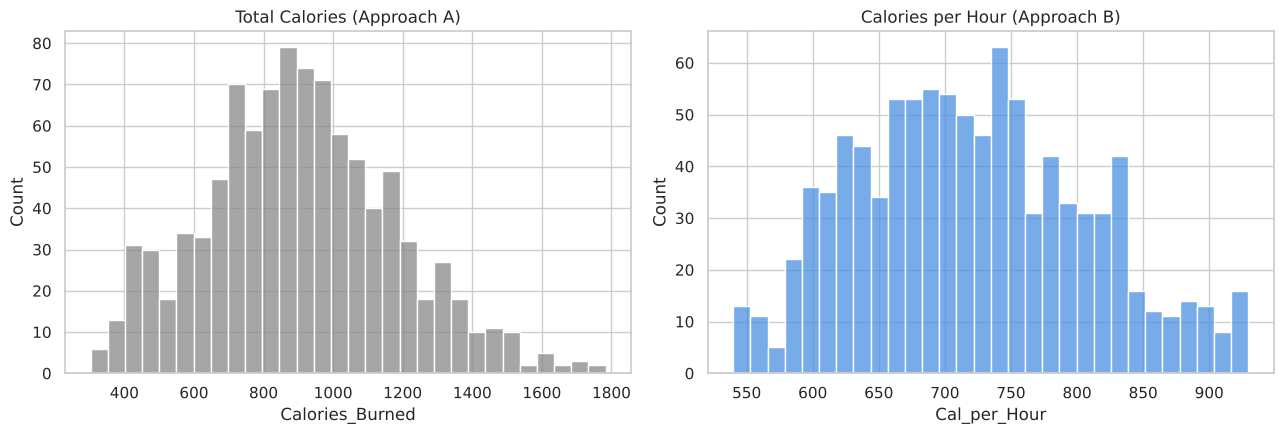

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["Calories_Burned"], bins=30, ax=axes[0], color="#888")
axes[0].set_title("Total Calories (Approach A)")
sns.histplot(df["Cal_per_Hour"], bins=30, ax=axes[1], color="#4a90e2")
axes[1].set_title("Calories per Hour (Approach B)")
plt.tight_layout(); plt.show()

Per hour is much tighter (about 540–930). The long right tail from long sessions disappears.

## 2. Workout Type: the Red Flag

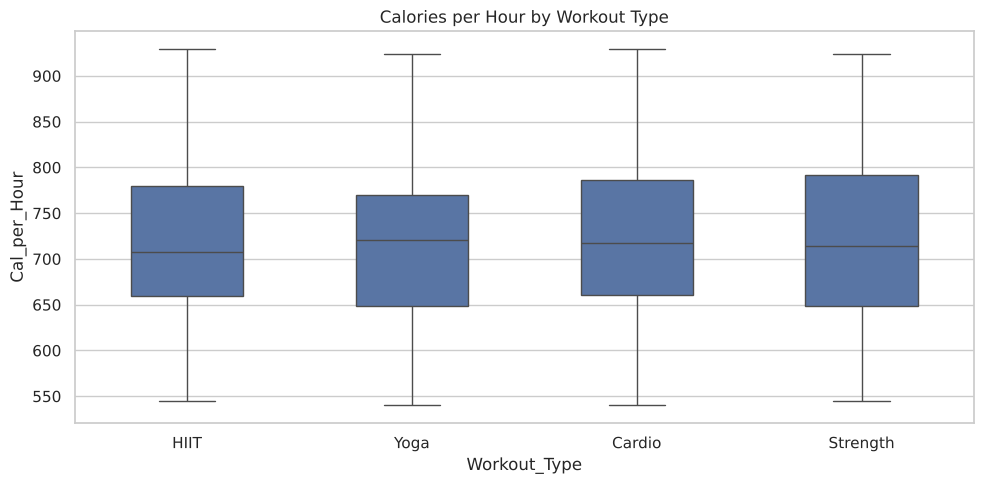

Workout_Type
Cardio      724.0
HIIT        717.0
Strength    724.0
Yoga        717.0
Name: Cal_per_Hour, dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
order = df.groupby("Workout_Type")["Cal_per_Hour"].mean().sort_values().index
sns.boxplot(data=df, x="Workout_Type", y="Cal_per_Hour", order=order, width=0.5, ax=ax)
ax.set_title("Calories per Hour by Workout Type")
plt.tight_layout(); plt.show()

display(df.groupby("Workout_Type")["Cal_per_Hour"].mean().round(0))

**Takeaway:** Cardio, HIIT, Strength and Yoga all burn about the same per hour. In real life an hour of HIIT and an hour of yoga are far apart. This is the strongest evidence that calories come from a **heart-rate formula that doesn't know the activity**.

## 3. Heart Rate vs Calories per Hour, by Gender

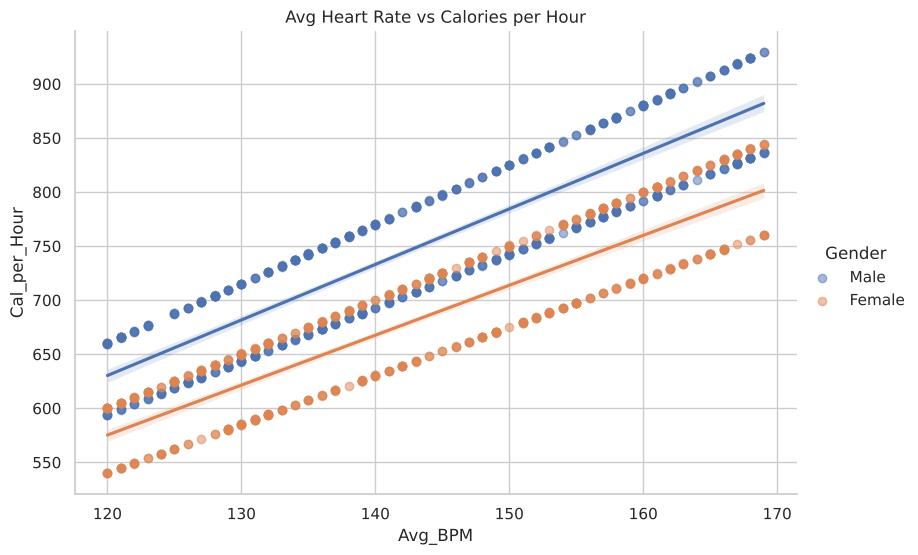

,Cal_per_Hour,Avg_BPM
Gender,,
Female,684.3,143.6
Male,753.1,143.9


In [5]:
g = sns.lmplot(data=df, x="Avg_BPM", y="Cal_per_Hour", hue="Gender",
               height=5.5, aspect=1.5, scatter_kws={"alpha": 0.5})
g.ax.set_title("Avg Heart Rate vs Calories per Hour")
plt.show()

display(df.groupby("Gender")[["Cal_per_Hour", "Avg_BPM"]].mean().round(1))

**Takeaway:** two clean, parallel lines, one per gender. At the **same heart rate**, men burn more per hour. That gender gap was hidden in Approach A because both genders train about the same length of time.

## 4. What Drives Calories per Hour?
Same two views as Approach A: correlation alone vs standardized effect together.

,Correlation (alone),Standardized effect (together)
Avg_BPM,0.81,0.82
Age,-0.33,-0.37
Male,0.40,0.38
Weight,0.26,0.01
Fat_Percentage,-0.17,-0.01
Experience_Level,0.01,0.00
Duration,0.01,-0.02


R² of this model: 0.947


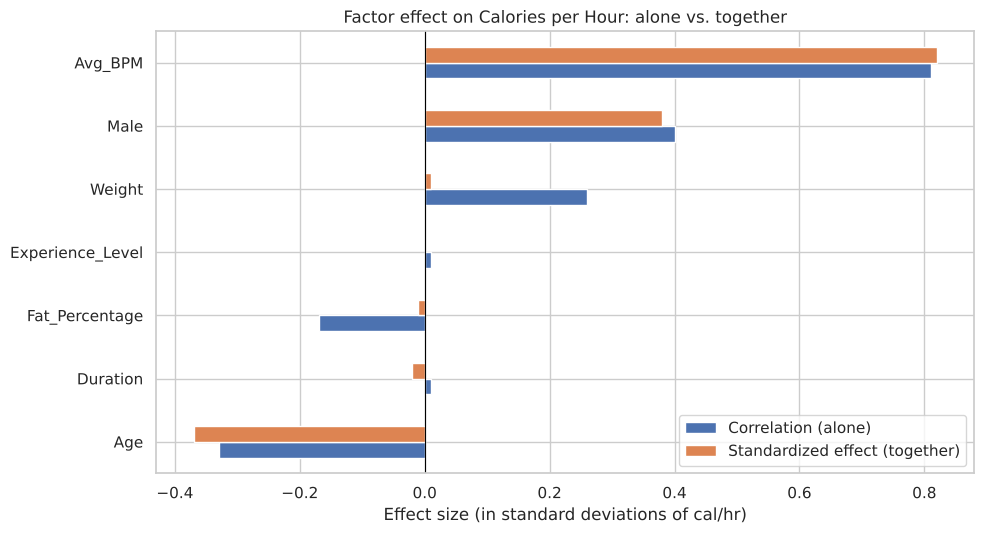

In [6]:
df["Male"] = (df["Gender"] == "Male").astype(int)
factors = ["Avg_BPM", "Age", "Male", "Weight", "Fat_Percentage", "Experience_Level", "Duration"]
X = StandardScaler().fit_transform(df[factors])
lr = LinearRegression().fit(X, df["Cal_per_Hour"])

effects = pd.DataFrame({
    "Correlation (alone)": df[factors].corrwith(df["Cal_per_Hour"]),
    "Standardized effect (together)": lr.coef_ / df["Cal_per_Hour"].std(),
}).round(2)
display(effects)
print(f"R² of this model: {lr.score(X, df['Cal_per_Hour']):.3f}")

effects.sort_values("Standardized effect (together)").plot.barh(figsize=(10, 5.5))
plt.axvline(0, color="black", lw=0.8)
plt.title("Factor effect on Calories per Hour: alone vs. together")
plt.xlabel("Effect size (in standard deviations of cal/hr)")
plt.tight_layout(); plt.show()

**Takeaway:** heart rate is the main driver, followed by gender (male = higher) and age (older = lower). Duration, experience and fat % drop to roughly zero.

## 5. Experience Stops Mattering

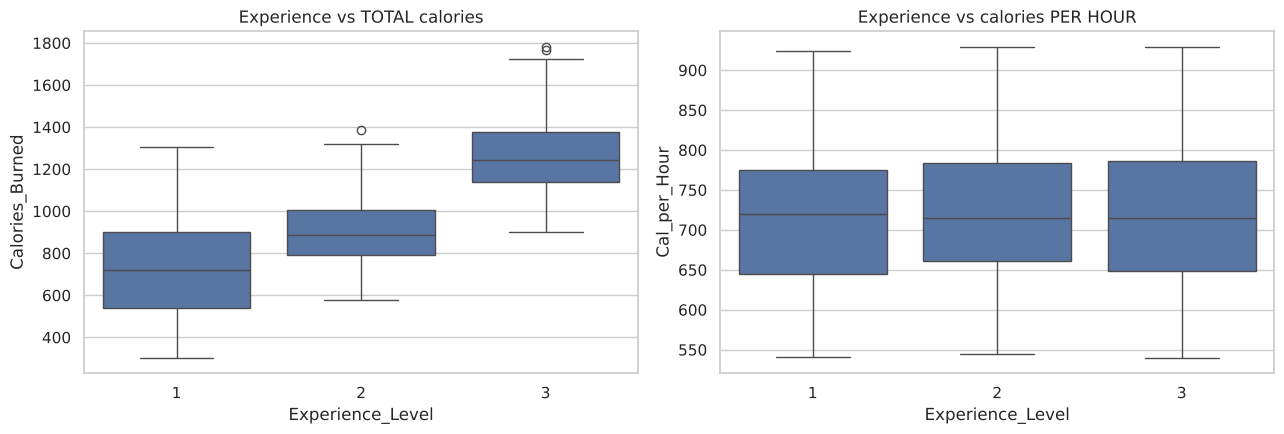

,Calories_Burned,Cal_per_Hour,Duration
Experience_Level,,,
1,726.4,718.8,1.0
2,901.9,722.4,1.2
3,1265.3,719.4,1.8


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="Experience_Level", y="Calories_Burned", ax=axes[0])
axes[0].set_title("Experience vs TOTAL calories")
sns.boxplot(data=df, x="Experience_Level", y="Cal_per_Hour", ax=axes[1])
axes[1].set_title("Experience vs calories PER HOUR")
plt.tight_layout(); plt.show()

display(df.groupby("Experience_Level")[["Calories_Burned", "Cal_per_Hour", "Duration"]].mean().round(1))

**Takeaway:** experienced members burn more **in total** only because they **stay longer**. Per hour, all three levels are the same. This answers the question *"does experience → more calories?"*: yes, but only through duration.

## 6. Low / Mid / High Intensity Tiers

In [8]:
labels = ["Low", "Mid", "High"]
df["Tier"] = pd.qcut(df["Cal_per_Hour"], 3, labels=labels)

display(df.groupby("Tier", observed=True)["Cal_per_Hour"].agg(["min", "max", "count"]).round(0))
display(df.groupby("Tier", observed=True)[["Avg_BPM", "Age", "Weight", "Duration", "Experience_Level"]].mean().round(1))

,min,max,count
Tier,,,
Low,540.0,675.0,325
Mid,675.0,755.0,324
High,756.0,930.0,324


,Avg_BPM,Age,Weight,Duration,Experience_Level
Tier,,,,,
Low,130.3,42.4,68.5,1.2,1.8
Mid,143.8,39.4,73.8,1.3,1.8
High,157.3,34.3,79.3,1.3,1.8


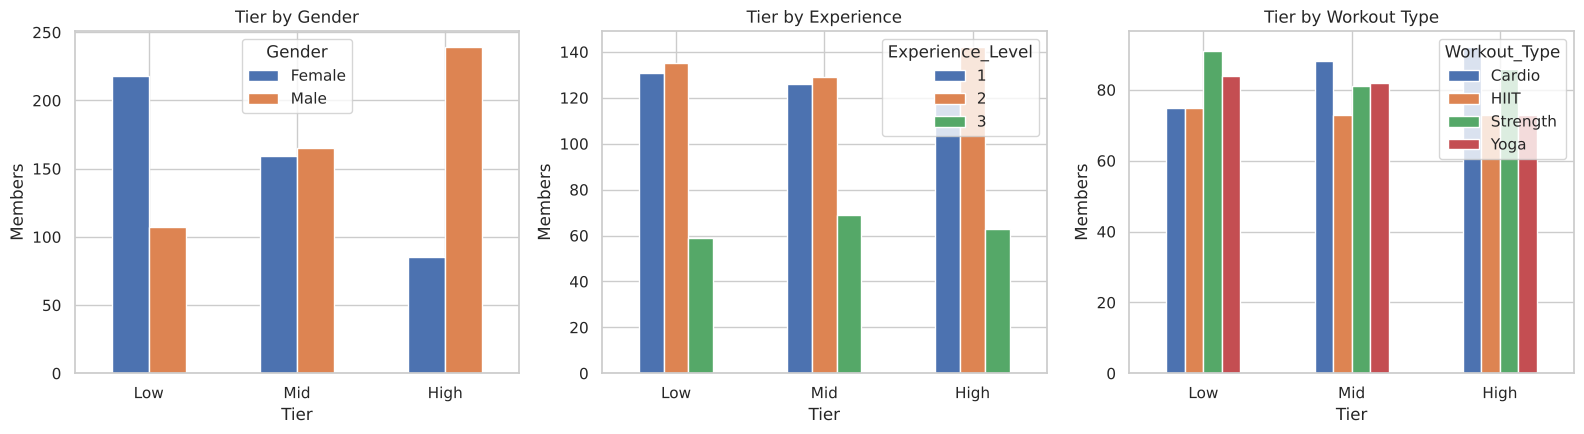

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pd.crosstab(df["Tier"], df["Gender"]).plot.bar(ax=axes[0], rot=0); axes[0].set_title("Tier by Gender")
pd.crosstab(df["Tier"], df["Experience_Level"]).plot.bar(ax=axes[1], rot=0); axes[1].set_title("Tier by Experience")
pd.crosstab(df["Tier"], df["Workout_Type"]).plot.bar(ax=axes[2], rot=0); axes[2].set_title("Tier by Workout Type")
for ax in axes: ax.set_ylabel("Members")
plt.tight_layout(); plt.show()

**Compare with Approach A:**
- Experience is spread **evenly** across tiers. The tiers no longer just mean "long session."
- Gender is **lopsided**: High is mostly men, Low is mostly women.
- Workout type is **flat** across tiers (the red flag again).

A classifier on these tiers has to use **heart rate, age and gender**. That makes it a more interesting target than total-calorie bins.

⚠️ For modeling, don't use `Calories_Burned` as an input. Per hour is just calories ÷ duration, so it gives away the answer.

## 7. The 1,500+ Sessions, Seen per Hour

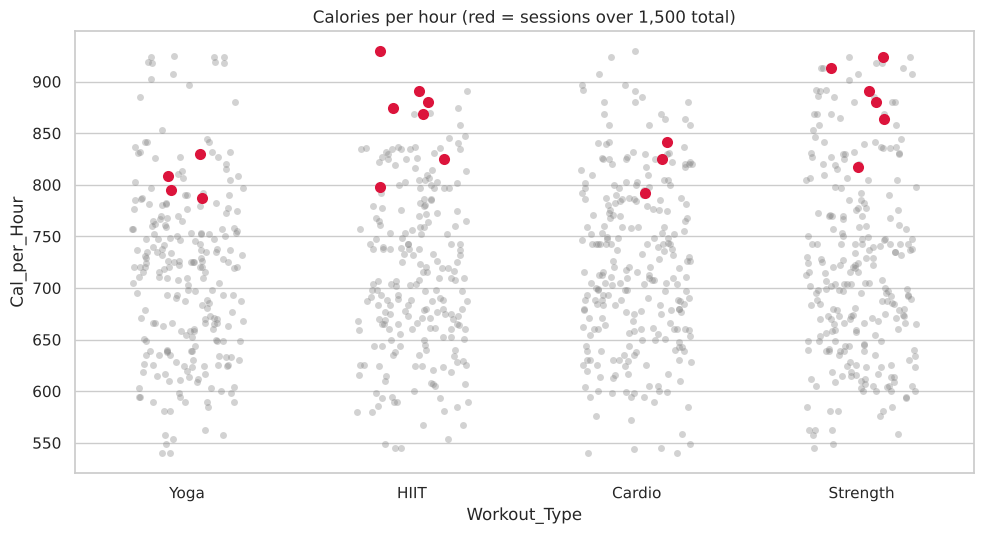

In [10]:
df["Over_1500"] = np.where(df["Calories_Burned"] > 1500, "Over 1,500 total", "Everyone else")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.stripplot(data=df[df.Over_1500 == "Everyone else"], x="Workout_Type", y="Cal_per_Hour",
              color="grey", alpha=0.35, jitter=0.25, ax=ax)
sns.stripplot(data=df[df.Over_1500 != "Everyone else"], x="Workout_Type", y="Cal_per_Hour",
              color="crimson", size=8, jitter=0.15, ax=ax)
ax.set_title("Calories per hour (red = sessions over 1,500 total)")
plt.tight_layout(); plt.show()

**Takeaway:** per hour, the 1,500+ sessions sit near the top but **inside** the normal range. They aren't extreme intensity. They're **high heart rate × nearly 2 hours**. The only implausible part is the activity label (yoga at about 800 kcal/hr).